# Experiment 1 — Fresh 30-Seed Validation (routing seeds 100–129)

Fresh-seed validation of Experiment 1. Re-evaluates EXACTLY the same 50 previously selected minimum-width GidNET reuse plans using 30 completely new SABRE routing seeds (100–129).

**Constraints:**
- Do NOT modify the original Experiment 1 notebook.
- Do NOT generate a new candidate set; do NOT rerun GidNET search; do NOT change plan selection.
- GidNET execution is ONLY used to reconstruct the exact previously selected plan from its saved representative `gidnet_seed`; the reconstructed signature MUST match the stored signature before routing.
- Same Python/Qiskit environment as GidNET experiments: Qiskit 0.45.3.
- Same topology/compiler settings as Experiment 1: `CouplingMap.from_heavy_hex(7)`, `routing_method='sabre'`, `layout_method='sabre'`, `optimization_level=1`.
- Never use routing seeds 42–46 in the fresh evaluation; never mix old/new seeds when computing fresh means.
- Compare rankings within each circuit only, never pool across circuits.

In [1]:
import ast
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.transpiler import CouplingMap
from gidnet.qubitreuse import GidNET

print('Qiskit version:', qiskit.__version__)
assert qiskit.__version__ == '0.45.3', f'Expected Qiskit 0.45.3, got {qiskit.__version__}'

REPO_DIR = Path(r'C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm')
BENCHMARK_DIR = Path(r'C:\Users\ASUS\Documents\Quantum computing\Qiskit\CaQR-main\CaQR-main\benchmarks')
OLD_RESULTS_DIR = REPO_DIR / 'experiment1_results'
OLD_RAW = OLD_RESULTS_DIR / 'experiment1_raw.csv'
OLD_PLAN = OLD_RESULTS_DIR / 'experiment1_plan_summary.csv'
OLD_CIRCUIT = OLD_RESULTS_DIR / 'experiment1_circuit_summary.csv'

OUT_DIR = REPO_DIR / 'experiment1_fresh30_validation'
FIG_DIR = OUT_DIR / 'figures'
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

CIRCUITS = ['system9.qasm', 'sym9_146.qasm', 'rd73_140.qasm', 'mini_alu_305.qasm', 'alu-bdd_288.qasm']
EXPECTED_PLAN_COUNTS = {'system9.qasm': 13, 'sym9_146.qasm': 9, 'rd73_140.qasm': 6, 'mini_alu_305.qasm': 16, 'alu-bdd_288.qasm': 6}

FRESH_ROUTING_SEEDS = list(range(100, 130))
assert len(FRESH_ROUTING_SEEDS) == 30
assert not any(42 <= s <= 46 for s in FRESH_ROUTING_SEEDS)

TARGET_COUPLING = CouplingMap.from_heavy_hex(7)
print('Target coupling size:', TARGET_COUPLING.size())
print('Benchmark dir exists:', BENCHMARK_DIR.exists())
print('Old results exist:', OLD_RAW.exists(), OLD_PLAN.exists(), OLD_CIRCUIT.exists())

Qiskit version: 0.45.3
Target coupling size: 115
Benchmark dir exists: True
Old results exist: True True True


## Reused Experiment 1 definitions (verbatim)
Copied exactly from `experiment1_physical_variation.ipynb`: `canonical_plan_signature`, `prepare_gidnet_input`, `normalize_active_reset`, `count_conditional_x`, plus `GidNET(...).compile_to_dynamic_circuit(iterations=20, draw=False)`.

In [2]:
def canonical_plan_signature(reuse_sequences):
    """
    Canonical representation of a GidNET reuse plan.
    - Order inside each reuse chain is preserved.
    - Order among different chains is ignored.
    """
    chains = [tuple(int(q) for q in chain) for chain in reuse_sequences]
    return tuple(sorted(chains))


def prepare_gidnet_input(qc):
    """
    Prepare a static benchmark circuit for GidNET.
    - Reject circuits that actually use classical bits/conditions.
    - Remove unused classical registers.
    - Remove idle qubits.
    - Preserve the quantum operations and their order.
    Returns: compact_qc, metadata
    """
    for item in qc.data:
        op = item.operation
        if len(item.clbits) > 0:
            raise ValueError(f'Circuit contains classical operands in operation: {op.name}')
        if getattr(op, 'condition', None) is not None:
            raise ValueError(f'Circuit contains a classically conditioned operation: {op.name}')
    active_qubits = sorted({qc.find_bit(q).index for item in qc.data for q in item.qubits})
    idle_qubits = sorted(set(range(qc.num_qubits)) - set(active_qubits))
    old_to_new = {old_idx: new_idx for new_idx, old_idx in enumerate(active_qubits)}
    compact = QuantumCircuit(len(active_qubits))
    for item in qc.data:
        op = item.operation
        new_qargs = [old_to_new[qc.find_bit(q).index] for q in item.qubits]
        compact.append(op.copy(), new_qargs, [])
    metadata = {
        'original_declared_qubits': qc.num_qubits,
        'original_clbits': qc.num_clbits,
        'active_qubits': len(active_qubits),
        'idle_qubits': idle_qubits,
        'old_to_new': old_to_new,
        'original_depth': qc.depth(),
        'compact_depth': compact.depth(),
        'original_ops': qc.count_ops(),
        'compact_ops': compact.count_ops(),
    }
    return compact, metadata


def normalize_active_reset(qc: QuantumCircuit) -> QuantumCircuit:
    """
    Normalize every reset into: measure -> conditional X. The input circuit is not modified.
    """
    new_qc = QuantumCircuit(*qc.qregs, *qc.cregs)
    last_measure_clbit = {}
    clbit_owner = {}
    total_resets = sum(1 for inst in qc.data if inst.operation.name == 'reset')
    aux_reg = None
    aux_next = 0
    for item in qc.data:
        instr = item.operation
        qargs = list(item.qubits)
        cargs = list(item.clbits)
        q_indices = [qc.find_bit(q).index for q in qargs]
        if instr.name == 'measure':
            q = qargs[0]
            c = cargs[0]
            q_idx = qc.find_bit(q).index
            c_idx = qc.find_bit(c).index
            old_owner = clbit_owner.get(c_idx)
            if old_owner is not None:
                last_measure_clbit.pop(old_owner, None)
            new_qc.append(instr, qargs, cargs)
            new_cbit = new_qc.clbits[c_idx]
            last_measure_clbit[q_idx] = new_cbit
            clbit_owner[c_idx] = q_idx
            continue
        if instr.name == 'reset':
            q = qargs[0]
            q_idx = qc.find_bit(q).index
            if q_idx in last_measure_clbit:
                cbit = last_measure_clbit[q_idx]
            else:
                if aux_reg is None:
                    aux_reg = ClassicalRegister(max(total_resets, 1), 'reset_aux')
                    new_qc.add_register(aux_reg)
                cbit = aux_reg[aux_next]
                aux_next += 1
                new_qc.measure(q, cbit)
            new_qc.x(q).c_if(cbit, 1)
            last_measure_clbit.pop(q_idx, None)
            continue
        new_qc.append(instr, qargs, cargs)
        for q_idx in q_indices:
            last_measure_clbit.pop(q_idx, None)
    return new_qc


def count_conditional_x(qc):
    """Count only X gates that have a classical condition."""
    count = 0
    for item in qc.data:
        op = item.operation
        if op.name == 'x' and op.condition is not None:
            count += 1
    return count

print('Experiment-1 definitions loaded.')


Experiment-1 definitions loaded.


## STEP 1 — Load old Experiment 1 results

In [3]:
old_raw = pd.read_csv(OLD_RAW)
old_plan = pd.read_csv(OLD_PLAN)
old_circuit = pd.read_csv(OLD_CIRCUIT)

print('old raw rows:', len(old_raw))
print('old unique plan rows:', len(old_plan))
print('circuits:', sorted(old_plan['circuit'].unique()))

assert len(old_raw) == 250, f'old raw rows = {len(old_raw)}, expected 250'
assert len(old_plan) == 50, f'old unique plan rows = {len(old_plan)}, expected 50'
assert sorted(old_plan['circuit'].unique()) == sorted(CIRCUITS)

for circ in CIRCUITS:
    sub = old_plan[old_plan['circuit'] == circ]
    n = len(sub)
    widths = sorted(sub['width'].unique())
    seeds = sorted(sub['gidnet_seed'].astype(int).tolist())
    print(f'{circ}: unique plans={n} (expected {EXPECTED_PLAN_COUNTS[circ]}), width={widths}, rep seeds={seeds}')
    assert n == EXPECTED_PLAN_COUNTS[circ], f'{circ}: got {n}, expected {EXPECTED_PLAN_COUNTS[circ]}'
    assert len(widths) == 1, f'{circ}: width not fixed: {widths}'

print('\nSTEP 1 OK: 250 raw rows, 50 plans, 5 circuits.')

old raw rows: 250
old unique plan rows: 50
circuits: ['alu-bdd_288.qasm', 'mini_alu_305.qasm', 'rd73_140.qasm', 'sym9_146.qasm', 'system9.qasm']
system9.qasm: unique plans=13 (expected 13), width=[7], rep seeds=[0, 1, 2, 4, 5, 6, 7, 12, 13, 14, 16, 17, 18]
sym9_146.qasm: unique plans=9 (expected 9), width=[5], rep seeds=[0, 1, 2, 3, 4, 6, 12, 13, 17]
rd73_140.qasm: unique plans=6 (expected 6), width=[5], rep seeds=[0, 2, 5, 9, 10, 11]
mini_alu_305.qasm: unique plans=16 (expected 16), width=[6], rep seeds=[0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 14, 15, 16, 17, 19]
alu-bdd_288.qasm: unique plans=6 (expected 6), width=[5], rep seeds=[0, 1, 2, 5, 6, 9]

STEP 1 OK: 250 raw rows, 50 plans, 5 circuits.


## STEP 2 — Reconstruct exactly the same 50 plans
For each row of `experiment1_plan_summary.csv`: reload QASM, apply identical `prepare_gidnet_input`, seed RNGs, run GidNET with `iterations=20`, check canonical signature + width + sanity. STOP on any mismatch. Run this cell fully before any routing.

In [4]:
verified_plans = []  # one entry per plan: stores raw_circ, circ_norm, metadata
failures = []

for _, row in old_plan.iterrows():
    circ_name = row['circuit']
    plan_id = row['plan_id']
    gidnet_seed = int(row['gidnet_seed'])
    stored_width = int(row['width'])
    stored_sig = ast.literal_eval(row['plan_signature'])
    stored_sig = tuple(tuple(int(x) for x in chain) for chain in stored_sig)

    qc_orig = QuantumCircuit.from_qasm_file(BENCHMARK_DIR / circ_name)
    qc_compact, prep_info = prepare_gidnet_input(qc_orig)

    random.seed(gidnet_seed)
    np.random.seed(gidnet_seed)
    g = GidNET(qc_compact)
    raw_circ = g.compile_to_dynamic_circuit(iterations=20, draw=False)

    reconstructed_sig = canonical_plan_signature(g.qubit_reuse_sequences)

    # ---- signature + width asserts (fail loudly) ----
    if reconstructed_sig != stored_sig:
        failures.append((circ_name, plan_id, gidnet_seed, stored_sig, reconstructed_sig))
        print(f'MISMATCH {circ_name} {plan_id} seed={gidnet_seed}')
        print('  stored:       ', stored_sig)
        print('  reconstructed:', reconstructed_sig)
        continue
    assert raw_circ.num_qubits == stored_width, (
        f'{circ_name} {plan_id}: width {raw_circ.num_qubits} != stored {stored_width}')

    # ---- Experiment-1 sanity checks ----
    flat = [q for chain in g.qubit_reuse_sequences for q in chain]
    missing = sorted(set(range(qc_compact.num_qubits)) - set(flat))
    duplicates = sorted({q for q in flat if flat.count(q) > 1})
    expected_boundaries = sum(len(c) - 1 for c in g.qubit_reuse_sequences)
    actual_resets = raw_circ.count_ops().get('reset', 0)
    sane = (len(missing) == 0 and len(duplicates) == 0 and expected_boundaries == actual_resets)
    if not sane:
        failures.append((circ_name, plan_id, gidnet_seed, stored_sig, reconstructed_sig))
        print(f'SANITY FAIL {circ_name} {plan_id} seed={gidnet_seed}: missing={missing} dups={duplicates} exp_bound={expected_boundaries} resets={actual_resets}')
        continue

    circ_norm = normalize_active_reset(raw_circ)
    verified_plans.append({
        'circuit': circ_name,
        'plan_id': plan_id,
        'gidnet_seed': gidnet_seed,
        'plan_signature': stored_sig,
        'plan_signature_str': row['plan_signature'],
        'width': stored_width,
        'raw_circ': raw_circ,
        'circ_norm': circ_norm,
        'raw_logical_depth': raw_circ.depth(),
        'normalized_logical_depth': circ_norm.depth(),
        'measurements': circ_norm.count_ops().get('measure', 0),
        'conditional_x': count_conditional_x(circ_norm),
    })
    print(f'OK {circ_name} {plan_id} seed={gidnet_seed} width={stored_width} depth={raw_circ.depth()}->{circ_norm.depth()}')

assert len(failures) == 0, f'{len(failures)} plan(s) failed signature/sanity checks — STOPPING. See output above.'
assert len(verified_plans) == 50, f'verified {len(verified_plans)}/50 plans'
print('\n50/50 plans reconstructed and verified')

OK system9.qasm P0 seed=0 width=7 depth=173->173
OK system9.qasm P1 seed=1 width=7 depth=172->176
OK system9.qasm P10 seed=16 width=7 depth=172->174
OK system9.qasm P11 seed=17 width=7 depth=164->168
OK system9.qasm P12 seed=18 width=7 depth=175->178
OK system9.qasm P2 seed=2 width=7 depth=175->178
OK system9.qasm P3 seed=4 width=7 depth=175->176
OK system9.qasm P4 seed=5 width=7 depth=173->175
OK system9.qasm P5 seed=6 width=7 depth=173->175
OK system9.qasm P6 seed=7 width=7 depth=172->174
OK system9.qasm P7 seed=12 width=7 depth=174->177
OK system9.qasm P8 seed=13 width=7 depth=173->177
OK system9.qasm P9 seed=14 width=7 depth=175->178
OK sym9_146.qasm P0 seed=0 width=5 depth=193->197
OK sym9_146.qasm P1 seed=1 width=5 depth=193->199
OK sym9_146.qasm P2 seed=2 width=5 depth=195->202
OK sym9_146.qasm P3 seed=3 width=5 depth=195->200
OK sym9_146.qasm P4 seed=4 width=5 depth=195->200
OK sym9_146.qasm P5 seed=6 width=5 depth=193->197
OK sym9_146.qasm P6 seed=12 width=5 depth=195->200
OK 

## STEP 3 — Normalized-plan ledger
Uses the exact same `normalize_active_reset(raw_circ)` protocol. Records raw/normalized depth, measurement and conditional-X counts, width.

In [5]:
assert len(verified_plans) == 50, 'STEP 2 must pass first: 50/50 plans reconstructed and verified'
ledger = pd.DataFrame([{
    'circuit': v['circuit'], 'plan_id': v['plan_id'], 'gidnet_seed': v['gidnet_seed'],
    'plan_signature': v['plan_signature_str'], 'width': v['width'],
    'raw_logical_depth': v['raw_logical_depth'],
    'normalized_logical_depth': v['normalized_logical_depth'],
    'measurements': v['measurements'], 'conditional_x': v['conditional_x'],
} for v in verified_plans])
display(ledger.sort_values(['circuit', 'plan_id']).reset_index(drop=True))
print('Normalized ledger rows:', len(ledger))

,circuit,plan_id,gidnet_seed,plan_signature,width,raw_logical_depth,normalized_logical_depth,measurements,conditional_x
0,alu-bdd_288.qasm,P0,0,"((0,), (1, 6), (2,), (3, 4), (5,))",5,49,51,2,2
1,alu-bdd_288.qasm,P1,1,"((0,), (1, 2, 4), (3,), (5,), (6,))",5,49,50,2,2
2,alu-bdd_288.qasm,P2,2,"((0, 4), (1, 6), (2,), (3,), (5,))",5,50,52,2,2
3,alu-bdd_288.qasm,P3,5,"((0,), (1, 6), (2, 4), (3,), (5,))",5,49,50,2,2
4,alu-bdd_288.qasm,P4,6,"((0, 4), (1, 2), (3,), (5,), (6,))",5,50,52,2,2
5,alu-bdd_288.qasm,P5,9,"((0,), (1, 2), (3, 4), (5,), (6,))",5,49,51,2,2
6,mini_alu_305.qasm,P0,0,"((1, 3), (2, 5), (4, 0), (6,), (7, 9), (8,))",6,101,101,4,4
7,mini_alu_305.qasm,P1,1,"((0,), (1, 3), (2, 5, 8), (4,), (6, 9), (7,))",6,102,103,4,4
8,mini_alu_305.qasm,P10,11,"((1, 5), (2, 8), (3,), (4, 0), (6,), (7, 9))",6,99,100,4,4
9,mini_alu_305.qasm,P11,14,"((1, 5, 8), (2, 0), (3,), (4,), (6, 9), (7,))",6,100,102,4,4


Normalized ledger rows: 50


## STEP 4 — Fresh 30-seed physical evaluation (50 × 30 = 1500 runs)
Routes each verified normalized circuit with seeds 100–129. Requires STEP 2 gate to have passed.

In [ ]:
assert len(verified_plans) == 50, 'Refusing to route: STEP 2 verification incomplete'

fresh_rows = []
for v in verified_plans:
    print(f"Routing {v['circuit']} {v['plan_id']} (gidnet_seed={v['gidnet_seed']})...")
    for rs in FRESH_ROUTING_SEEDS:
        tp = transpile(
            v['circ_norm'],
            coupling_map=TARGET_COUPLING,
            routing_method='sabre',
            layout_method='sabre',
            optimization_level=1,
            seed_transpiler=rs,
        )
        fresh_rows.append({
            'circuit': v['circuit'],
            'plan_id': v['plan_id'],
            'gidnet_seed': v['gidnet_seed'],
            'plan_signature': v['plan_signature_str'],
            'width': v['width'],
            'raw_logical_depth': v['raw_logical_depth'],
            'normalized_logical_depth': v['normalized_logical_depth'],
            'routing_seed': rs,
            'swap_count': tp.count_ops().get('swap', 0),
            'routed_depth': tp.depth(),
            'cx_count': tp.count_ops().get('cx', 0),
            'measurements': v['measurements'],
            'conditional_x': v['conditional_x'],
        })

fresh30_raw = pd.DataFrame(fresh_rows)
print('fresh rows:', len(fresh30_raw))
assert len(fresh30_raw) == 1500, f'expected 1500 rows, got {len(fresh30_raw)}'
per_plan_counts = fresh30_raw.groupby(['circuit', 'plan_id'])['routing_seed'].agg(['count', 'nunique'])
assert (per_plan_counts['count'] == 30).all(), per_plan_counts
assert (per_plan_counts['nunique'] == 30).all(), per_plan_counts
assert set(fresh30_raw['routing_seed'].unique()) == set(FRESH_ROUTING_SEEDS)
assert not any((fresh30_raw['routing_seed'] >= 42) & (fresh30_raw['routing_seed'] <= 46))
print('STEP 4 OK: every plan has exactly 30 distinct fresh routing seeds.')

Routing system9.qasm P0 (gidnet_seed=0)...


2026-09-30 21:19:07,901 - INFO - Pass: UnrollCustomDefinitions - 0.00000 (ms)
2026-09-30 21:19:07,901 - INFO - Begin BasisTranslator from source basis {('u3', 1)} to target basis {'rx', 'measure', 'cx', 'barrier', 'p', 'rz', 'z', 'ry', 'u', 'x', 'reset', 'snapshot', 'delay'}.
2026-09-30 21:19:07,910 - INFO - Basis translation path search completed in 0.000s.
2026-09-30 21:19:07,917 - INFO - Basis translation paths composed in 0.002s.
2026-09-30 21:19:07,918 - INFO - Basis translation instructions replaced in 0.000s.
2026-09-30 21:19:07,922 - INFO - Pass: BasisTranslator - 19.04511 (ms)
2026-09-30 21:19:07,985 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-30 21:19:07,993 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-30 21:19:07,995 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-30 21:19:07,995 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-30 21:19:07,995 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-30 21:19:07,995 - INFO - Pass: BarrierBeforeFina

Routing system9.qasm P1 (gidnet_seed=1)...


2026-09-30 21:19:11,658 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:11,658 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-30 21:19:11,658 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:11,666 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:11,666 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:11,670 - INFO - Pass: Optimize1qGatesDecomposition - 4.36664 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: CXCancellation - 5.89728 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:11,676 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:11,685 - INFO - Total Transpile Time - 108.52051 (ms)
2026-09-30 21:19:11,699 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-30 21:19:11,699 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)


Routing system9.qasm P10 (gidnet_seed=16)...


2026-09-30 21:19:15,076 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-30 21:19:15,079 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:15,079 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-30 21:19:15,079 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:15,079 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:15,079 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:15,087 - INFO - Pass: Optimize1qGatesDecomposition - 8.01277 (ms)
2026-09-30 21:19:15,093 - INFO - Pass: CXCancellation - 5.77807 (ms)
2026-09-30 21:19:15,093 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:15,096 - INFO - Pass: Depth - 0.80729 (ms)
2026-09-30 21:19:15,097 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:15,097 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:15,097 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:15,097 - INFO - Total Transpile Time - 98.97304 (ms)
2026-09-30 21:19:15,114 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
202

... (12 outputs left out)

Routing system9.qasm P6 (gidnet_seed=7)...


2026-09-30 21:19:39,793 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:39,793 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:39,801 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:39,801 - INFO - Total Transpile Time - 99.72548 (ms)
2026-09-30 21:19:39,818 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-30 21:19:39,818 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-30 21:19:39,821 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-30 21:19:39,821 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-30 21:19:39,821 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-30 21:19:39,826 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.35262 (ms)
2026-09-30 21:19:39,853 - INFO - Pass: SabreLayout - 26.46899 (ms)
2026-09-30 21:19:39,859 - INFO - Pass: CheckMap - 1.05619 (ms)
2026-09-30 21:19:39,859 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-30 21:19:39,863 - INFO - Pass: HighLevelSynthesis - 1.63245 (ms)
2026-09-30 21:19:39,864 - INFO 

Routing system9.qasm P7 (gidnet_seed=12)...


2026-09-30 21:19:43,673 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:43,676 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:43,676 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:43,689 - INFO - Pass: Optimize1qGatesDecomposition - 13.55505 (ms)
2026-09-30 21:19:43,693 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-30 21:19:43,693 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:43,698 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-30 21:19:43,698 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:43,698 - INFO - Pass: Size - 0.00000 (ms)
2026-09-30 21:19:43,698 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-30 21:19:43,709 - INFO - Pass: Optimize1qGatesDecomposition - 11.46698 (ms)
2026-09-30 21:19:43,709 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-30 21:19:43,714 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-30 21:19:43,714 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-30 21:19:43,714 - INFO - Pass: FixedPoint - 0.00000 (m

## STEP 5 — Fresh plan-level summary (50 rows)

In [17]:
fresh30_plan_summary = (
    fresh30_raw.groupby(
        ['circuit', 'plan_id', 'gidnet_seed', 'plan_signature', 'width', 'raw_logical_depth', 'normalized_logical_depth'],
        as_index=False).agg(
        fresh_mean_swaps=('swap_count', 'mean'),
        fresh_std_swaps=('swap_count', lambda x: np.std(x, ddof=0)),
        fresh_min_swaps=('swap_count', 'min'),
        fresh_max_swaps=('swap_count', 'max'),
        fresh_mean_routed_depth=('routed_depth', 'mean'),
        fresh_std_routed_depth=('routed_depth', lambda x: np.std(x, ddof=0)),
        fresh_min_routed_depth=('routed_depth', 'min'),
        fresh_max_routed_depth=('routed_depth', 'max'),
        num_fresh_routing_trials=('routing_seed', 'count'),
    ))
assert len(fresh30_plan_summary) == 50, len(fresh30_plan_summary)
display(fresh30_plan_summary.sort_values(['circuit', 'plan_id']).reset_index(drop=True))
print('STEP 5 OK: 50 plan rows.')

,circuit,plan_id,gidnet_seed,plan_signature,width,raw_logical_depth,normalized_logical_depth,fresh_mean_swaps,fresh_std_swaps,fresh_min_swaps,fresh_max_swaps,fresh_mean_routed_depth,fresh_std_routed_depth,fresh_min_routed_depth,fresh_max_routed_depth,num_fresh_routing_trials
0,alu-bdd_288.qasm,P0,0,"((0,), (1, 6), (2,), (3, 4), (5,))",5,49,51,20.900000,1.220656,20,23,80.266667,1.289272,79,83,30
1,alu-bdd_288.qasm,P1,1,"((0,), (1, 2, 4), (3,), (5,), (6,))",5,49,50,23.433333,1.520599,21,25,79.000000,1.732051,77,82,30
2,alu-bdd_288.qasm,P2,2,"((0, 4), (1, 6), (2,), (3,), (5,))",5,50,52,20.766667,0.422953,20,21,78.333333,0.829993,77,81,30
3,alu-bdd_288.qasm,P3,5,"((0,), (1, 6), (2, 4), (3,), (5,))",5,49,50,22.033333,1.048279,20,24,78.366667,1.401983,77,82,30
4,alu-bdd_288.qasm,P4,6,"((0, 4), (1, 2), (3,), (5,), (6,))",5,50,52,21.300000,0.458258,21,22,80.533333,2.077392,77,83,30
5,alu-bdd_288.qasm,P5,9,"((0,), (1, 2), (3, 4), (5,), (6,))",5,49,51,22.466667,1.056199,21,24,82.633333,1.580787,80,85,30
6,mini_alu_305.qasm,P0,0,"((1, 3), (2, 5), (4, 0), (6,), (7, 9), (8,))",6,101,101,45.500000,1.408309,43,48,165.233333,2.011357,161,170,30
7,mini_alu_305.qasm,P1,1,"((0,), (1, 3), (2, 5, 8), (4,), (6, 9), (7,))",6,102,103,42.966667,1.196755,42,47,159.166667,1.790407,156,165,30
8,mini_alu_305.qasm,P10,11,"((1, 5), (2, 8), (3,), (4, 0), (6,), (7, 9))",6,99,100,43.133333,1.477235,41,47,155.966667,3.135637,152,163,30
9,mini_alu_305.qasm,P11,14,"((1, 5, 8), (2, 0), (3,), (4,), (6, 9), (7,))",6,100,102,44.800000,0.871780,44,47,159.033333,2.762648,155,164,30


STEP 5 OK: 50 plan rows.


## STEP 6 — Fresh circuit-level summary (5 rows)

In [18]:
circuit_rows = []
for circ in CIRCUITS:
    sub = fresh30_plan_summary[fresh30_plan_summary['circuit'] == circ]
    assert len(sub) == EXPECTED_PLAN_COUNTS[circ]
    width = int(sub['width'].iloc[0])
    assert (sub['width'] == width).all()
    best_sw = float(sub['fresh_mean_swaps'].min()); worst_sw = float(sub['fresh_mean_swaps'].max())
    sw_spread = worst_sw - best_sw
    rel_sw = sw_spread / best_sw if best_sw != 0 else np.nan
    best_d = float(sub['fresh_mean_routed_depth'].min()); worst_d = float(sub['fresh_mean_routed_depth'].max())
    d_spread = worst_d - best_d
    rel_d = d_spread / best_d if best_d != 0 else np.nan
    med_sw_std = float(sub['fresh_std_swaps'].median()); med_d_std = float(sub['fresh_std_routed_depth'].median())
    circuit_rows.append({
        'circuit': circ,
        'num_plans': len(sub),
        'fixed_width': width,
        'best_fresh_mean_swaps': best_sw,
        'worst_fresh_mean_swaps': worst_sw,
        'absolute_fresh_swap_spread': sw_spread,
        'relative_fresh_swap_spread': rel_sw,
        'best_fresh_mean_routed_depth': best_d,
        'worst_fresh_mean_routed_depth': worst_d,
        'absolute_fresh_routed_depth_spread': d_spread,
        'relative_fresh_routed_depth_spread': rel_d,
        'median_fresh_within_plan_swap_std': med_sw_std,
        'median_fresh_within_plan_depth_std': med_d_std,
        'fresh_swap_spread_over_median_std': sw_spread / med_sw_std if med_sw_std else np.nan,
        'fresh_depth_spread_over_median_std': d_spread / med_d_std if med_d_std else np.nan,
    })
fresh30_circuit_summary = pd.DataFrame(circuit_rows)
assert len(fresh30_circuit_summary) == 5
display(fresh30_circuit_summary)
print('STEP 6 OK: 5 circuit rows.')

,circuit,num_plans,fixed_width,best_fresh_mean_swaps,worst_fresh_mean_swaps,absolute_fresh_swap_spread,relative_fresh_swap_spread,best_fresh_mean_routed_depth,worst_fresh_mean_routed_depth,absolute_fresh_routed_depth_spread,relative_fresh_routed_depth_spread,median_fresh_within_plan_swap_std,median_fresh_within_plan_depth_std,fresh_swap_spread_over_median_std,fresh_depth_spread_over_median_std
0,system9.qasm,13,7,84.833333,96.166667,11.333333,0.133595,283.900000,304.433333,20.533333,0.072326,2.805748,6.332368,4.039327,3.242599
1,sym9_146.qasm,9,5,77.433333,88.866667,11.433333,0.147654,306.266667,321.333333,15.066667,0.049195,5.339163,4.884897,2.141409,3.084336
2,rd73_140.qasm,6,5,52.300000,60.333333,8.033333,0.153601,212.866667,226.633333,13.766667,0.064673,3.385270,3.292696,2.373026,4.180971
3,mini_alu_305.qasm,16,6,41.666667,46.800000,5.133333,0.123200,150.966667,165.233333,14.266667,0.094502,1.323430,2.427693,3.878811,5.876635
4,alu-bdd_288.qasm,6,5,20.766667,23.433333,2.666667,0.128411,78.333333,82.633333,4.300000,0.054894,1.052239,1.491385,2.534279,2.883226


STEP 6 OK: 5 circuit rows.


## STEP 7 — Compare old 5-seed vs fresh 30-seed (per-circuit rank stability)
Join on `circuit + plan_id` (never row position). Spearman is the main ranking-stability metric; Pearson is secondary/descriptive.

In [19]:
def _rankdata(a):
    a = np.asarray(a, dtype=float)
    order = np.argsort(a, kind='mergesort')
    ranks = np.empty(len(a), dtype=float)
    i = 0
    while i < len(a):
        j = i
        while j + 1 < len(a) and a[order[j + 1]] == a[order[i]]:
            j += 1
        avg = (i + j) / 2.0 + 1.0
        ranks[order[i:j + 1]] = avg
        i = j + 1
    return ranks

def _pearson(x, y):
    x = np.asarray(x, dtype=float); y = np.asarray(y, dtype=float)
    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])

def _spearman(x, y):
    return _pearson(_rankdata(x), _rankdata(y))

merged = old_plan[['circuit', 'plan_id', 'gidnet_seed', 'plan_signature', 'width', 'mean_swaps', 'mean_routed_depth']].merge(
    fresh30_plan_summary[['circuit', 'plan_id', 'fresh_mean_swaps', 'fresh_mean_routed_depth']],
    on=['circuit', 'plan_id'], how='inner', validate='one_to_one')
assert len(merged) == 50, len(merged)

corr_rows, comp_rows = [], []
for circ in CIRCUITS:
    sub = merged[merged['circuit'] == circ]
    sp_sw = _spearman(sub['mean_swaps'], sub['fresh_mean_swaps'])
    pe_sw = _pearson(sub['mean_swaps'], sub['fresh_mean_swaps'])
    sp_d = _spearman(sub['mean_routed_depth'], sub['fresh_mean_routed_depth'])
    pe_d = _pearson(sub['mean_routed_depth'], sub['fresh_mean_routed_depth'])
    old_best_sw = str(sub.loc[sub['mean_swaps'].idxmin(), 'plan_id'])
    fresh_best_sw = str(sub.loc[sub['fresh_mean_swaps'].idxmin(), 'plan_id'])
    old_best_d = str(sub.loc[sub['mean_routed_depth'].idxmin(), 'plan_id'])
    fresh_best_d = str(sub.loc[sub['fresh_mean_routed_depth'].idxmin(), 'plan_id'])
    corr_rows.append({'circuit': circ, 'num_plans': len(sub),
        'spearman_old5_vs_fresh30_swaps': sp_sw, 'pearson_old5_vs_fresh30_swaps': pe_sw,
        'spearman_old5_vs_fresh30_depth': sp_d, 'pearson_old5_vs_fresh30_depth': pe_d})
    comp_rows.append({'circuit': circ, 'num_plans': len(sub),
        'old_best_swap_plan': old_best_sw, 'fresh_best_swap_plan': fresh_best_sw,
        'same_best_swap_plan': old_best_sw == fresh_best_sw,
        'old_best_depth_plan': old_best_d, 'fresh_best_depth_plan': fresh_best_d,
        'same_best_depth_plan': old_best_d == fresh_best_d})
    print(f'{circ}: spearman_sw={sp_sw:.3f} spearman_depth={sp_d:.3f} '
          f'best_sw(old={old_best_sw},fresh={fresh_best_sw},same={old_best_sw == fresh_best_sw}) '
          f'best_d(old={old_best_d},fresh={fresh_best_d},same={old_best_d == fresh_best_d})')

rank_correlations = pd.DataFrame(corr_rows)
best_plan_comparison = pd.DataFrame(comp_rows)
display(rank_correlations)
display(best_plan_comparison)

system9.qasm: spearman_sw=0.890 spearman_depth=0.803 best_sw(old=P7,fresh=P7,same=True) best_d(old=P11,fresh=P11,same=True)
sym9_146.qasm: spearman_sw=0.967 spearman_depth=0.717 best_sw(old=P1,fresh=P1,same=True) best_d(old=P1,fresh=P1,same=True)
rd73_140.qasm: spearman_sw=0.943 spearman_depth=1.000 best_sw(old=P3,fresh=P3,same=True) best_d(old=P4,fresh=P4,same=True)
mini_alu_305.qasm: spearman_sw=0.931 spearman_depth=0.975 best_sw(old=P2,fresh=P2,same=True) best_d(old=P5,fresh=P5,same=True)
alu-bdd_288.qasm: spearman_sw=1.000 spearman_depth=0.886 best_sw(old=P2,fresh=P2,same=True) best_d(old=P3,fresh=P2,same=False)


,circuit,num_plans,spearman_old5_vs_fresh30_swaps,pearson_old5_vs_fresh30_swaps,spearman_old5_vs_fresh30_depth,pearson_old5_vs_fresh30_depth
0,system9.qasm,13,0.890110,0.931399,0.803302,0.864797
1,sym9_146.qasm,9,0.966667,0.915084,0.716667,0.890665
2,rd73_140.qasm,6,0.942857,0.936730,1.000000,0.930226
3,mini_alu_305.qasm,16,0.931270,0.965044,0.974964,0.908974
4,alu-bdd_288.qasm,6,1.000000,0.963010,0.885714,0.944053


,circuit,num_plans,old_best_swap_plan,fresh_best_swap_plan,same_best_swap_plan,old_best_depth_plan,fresh_best_depth_plan,same_best_depth_plan
0,system9.qasm,13,P7,P7,True,P11,P11,True
1,sym9_146.qasm,9,P1,P1,True,P1,P1,True
2,rd73_140.qasm,6,P3,P3,True,P4,P4,True
3,mini_alu_305.qasm,16,P2,P2,True,P5,P5,True
4,alu-bdd_288.qasm,6,P2,P2,True,P3,P2,False


## STEP 8 — Old-vs-fresh circuit table

In [20]:
old_c = old_circuit.set_index('circuit')
fresh_c = fresh30_circuit_summary.set_index('circuit')
rc = rank_correlations.set_index('circuit')
bp = best_plan_comparison.set_index('circuit')
table_rows = []
for circ in CIRCUITS:
    table_rows.append({
        'circuit': circ,
        'num_plans': int(fresh_c.loc[circ, 'num_plans']),
        'fixed_width': int(fresh_c.loc[circ, 'fixed_width']),
        'old5_relative_swap_spread_pct': float(old_c.loc[circ, 'relative_swap_spread']) * 100.0,
        'fresh30_relative_swap_spread_pct': float(fresh_c.loc[circ, 'relative_fresh_swap_spread']) * 100.0,
        'old5_relative_depth_spread_pct': float(old_c.loc[circ, 'relative_routed_depth_spread']) * 100.0,
        'fresh30_relative_depth_spread_pct': float(fresh_c.loc[circ, 'relative_fresh_routed_depth_spread']) * 100.0,
        'spearman_swap_rank': float(rc.loc[circ, 'spearman_old5_vs_fresh30_swaps']),
        'spearman_depth_rank': float(rc.loc[circ, 'spearman_old5_vs_fresh30_depth']),
        'same_best_swap_plan': bool(bp.loc[circ, 'same_best_swap_plan']),
        'same_best_depth_plan': bool(bp.loc[circ, 'same_best_depth_plan']),
    })
old_vs_fresh_table = pd.DataFrame(table_rows)
display(old_vs_fresh_table)
print('STEP 8 OK.')

,circuit,num_plans,fixed_width,old5_relative_swap_spread_pct,fresh30_relative_swap_spread_pct,old5_relative_depth_spread_pct,fresh30_relative_depth_spread_pct,spearman_swap_rank,spearman_depth_rank,same_best_swap_plan,same_best_depth_plan
0,system9.qasm,13,7,14.186047,13.359528,6.171983,7.232594,0.890110,0.803302,True,True
1,sym9_146.qasm,9,5,19.363395,14.765390,6.036745,4.919460,0.966667,0.716667,True,True
2,rd73_140.qasm,6,5,19.844358,15.360102,6.974552,6.467272,0.942857,1.000000,True,True
3,mini_alu_305.qasm,16,6,12.500000,12.320000,9.479306,9.450210,0.931270,0.974964,True,True
4,alu-bdd_288.qasm,6,5,10.476190,12.841091,5.897436,5.489362,1.000000,0.885714,True,False


STEP 8 OK.


## STEP 9 — Plots (matplotlib only, 300 dpi)

matplotlib: 3.11.1


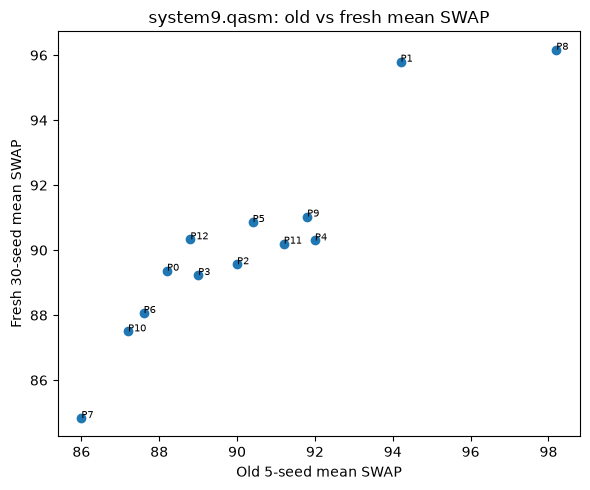

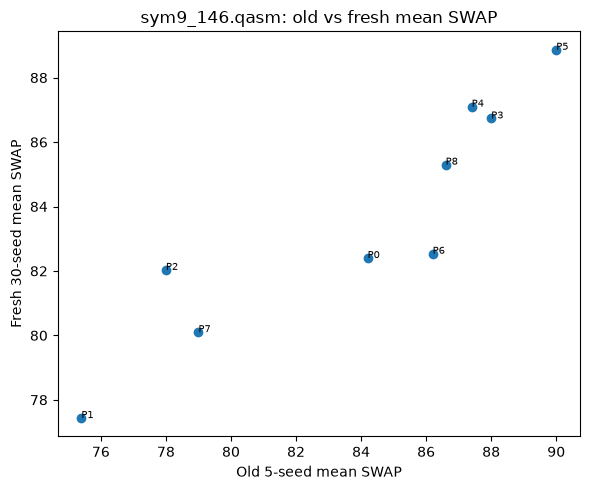

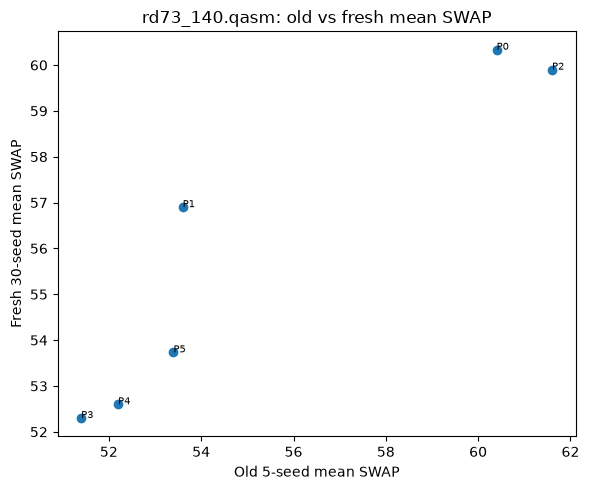

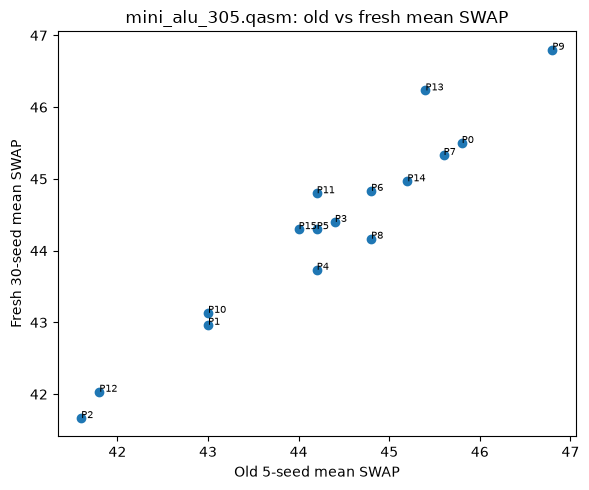

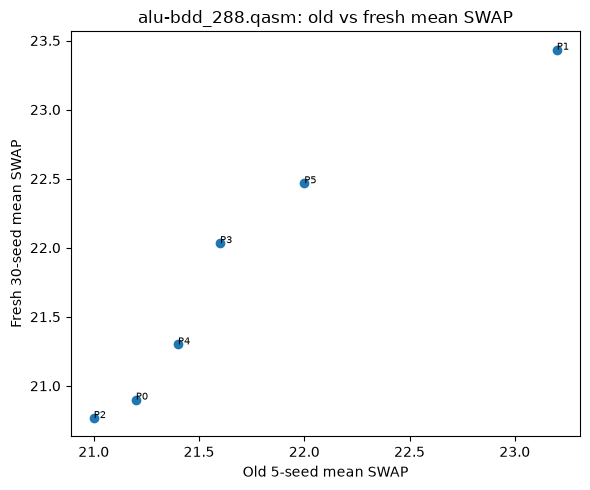

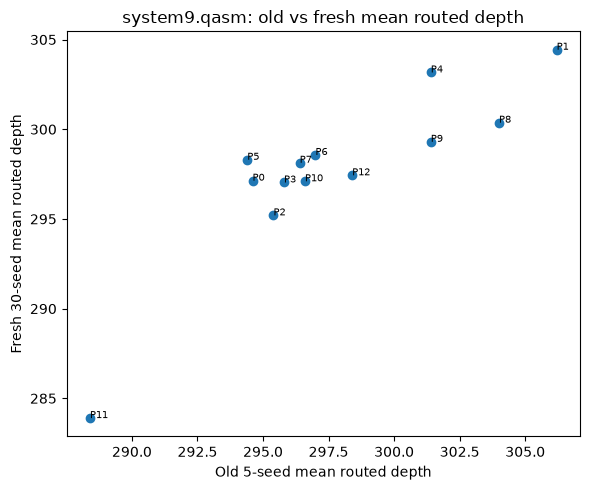

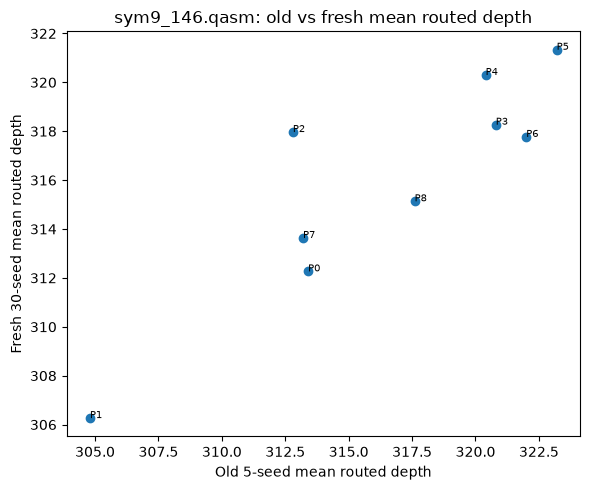

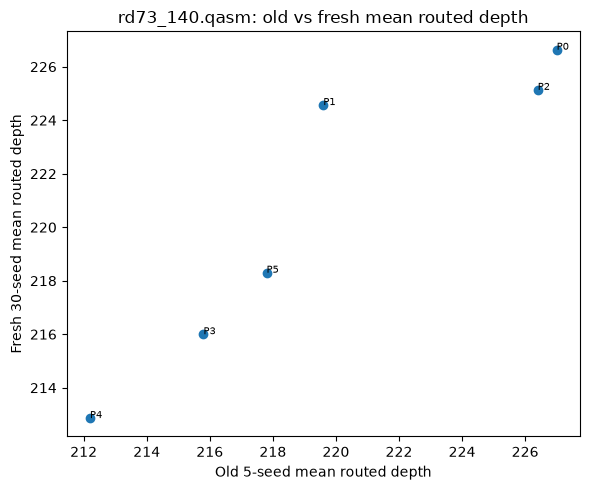

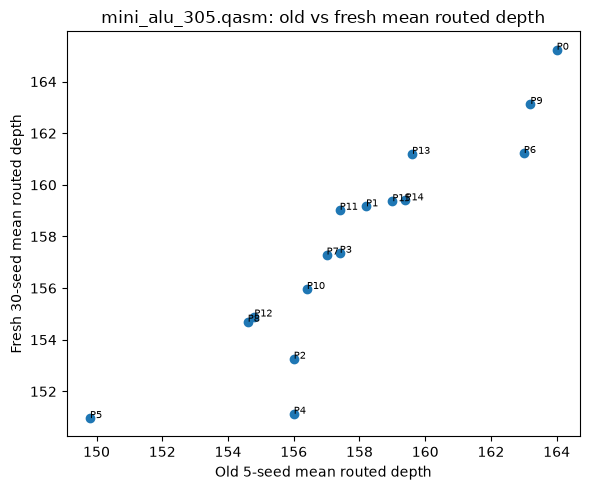

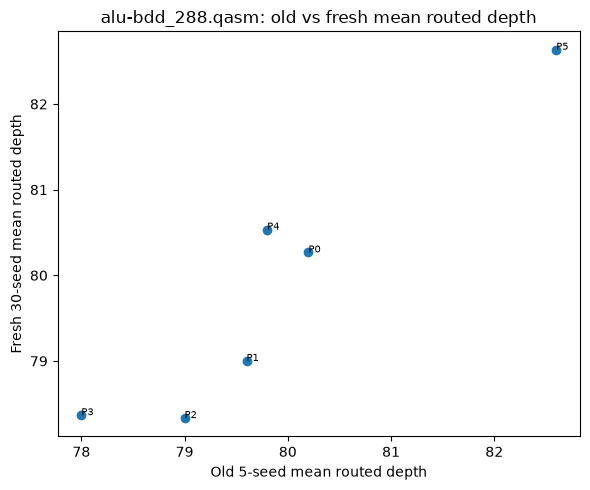

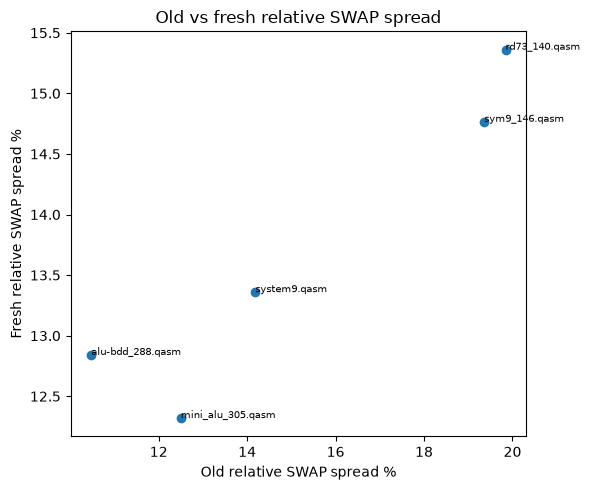

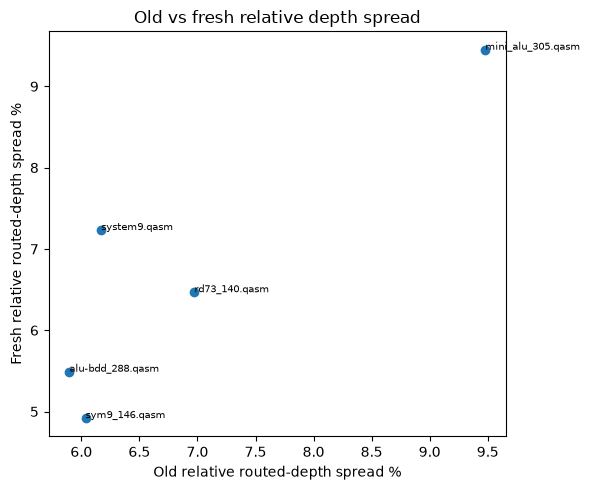

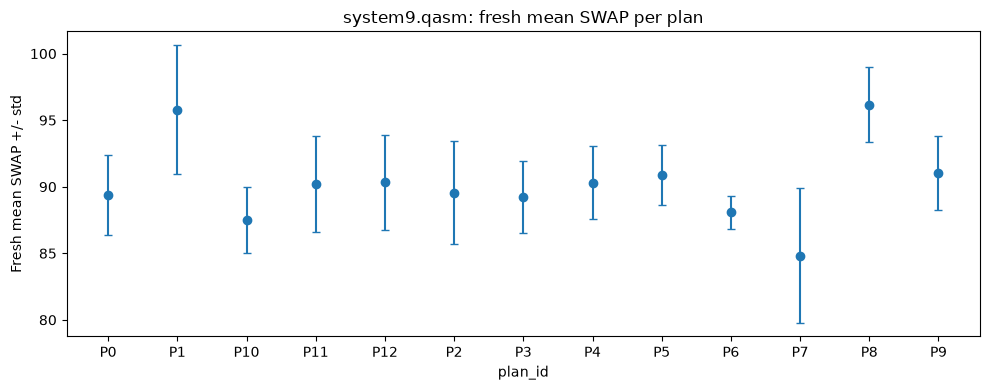

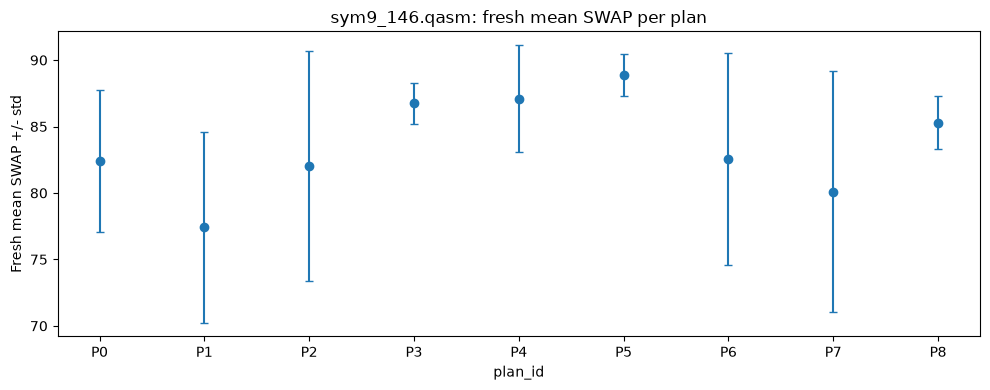

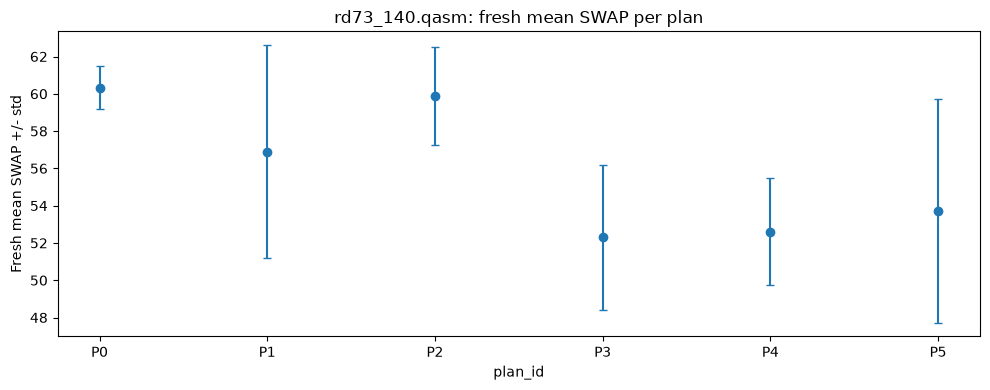

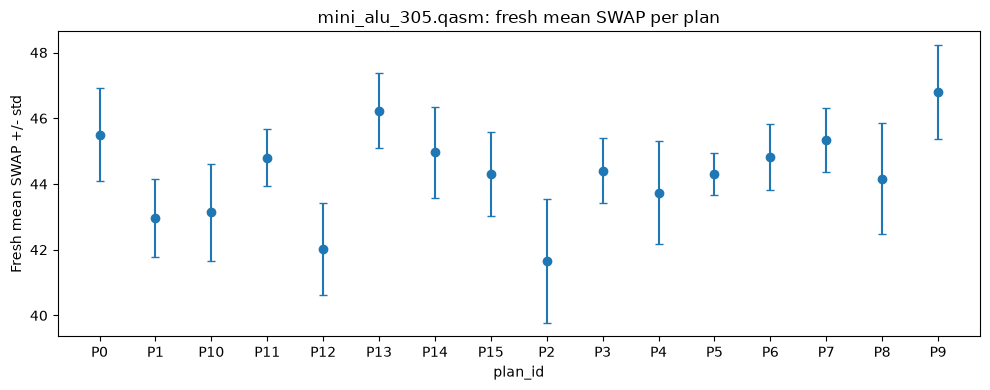

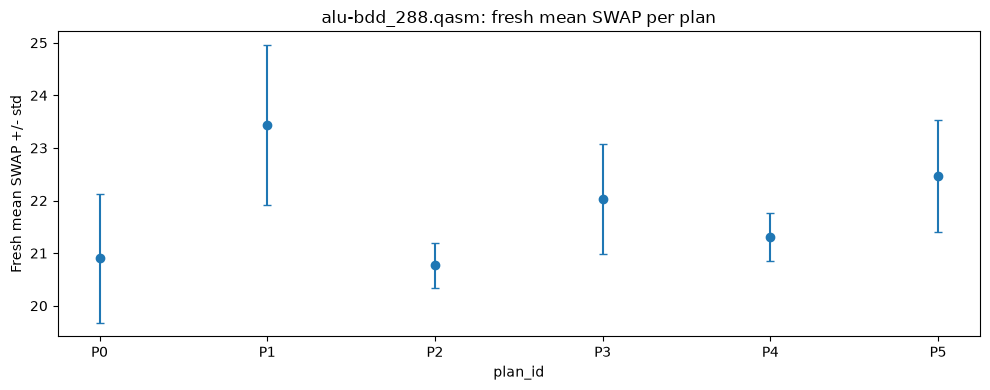

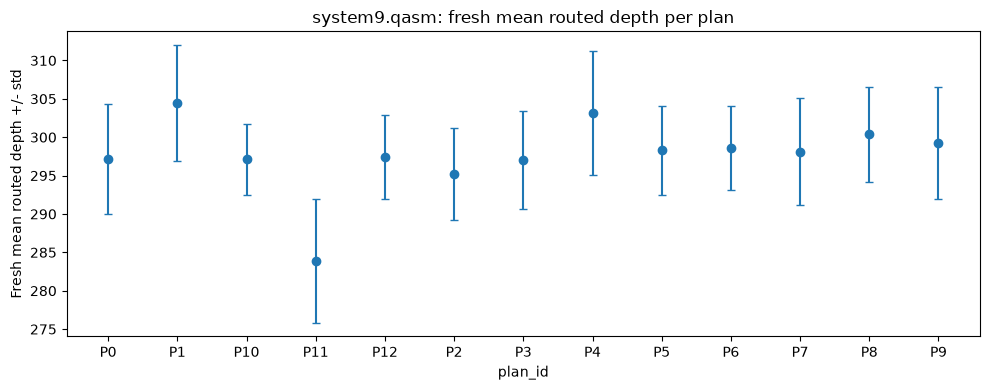

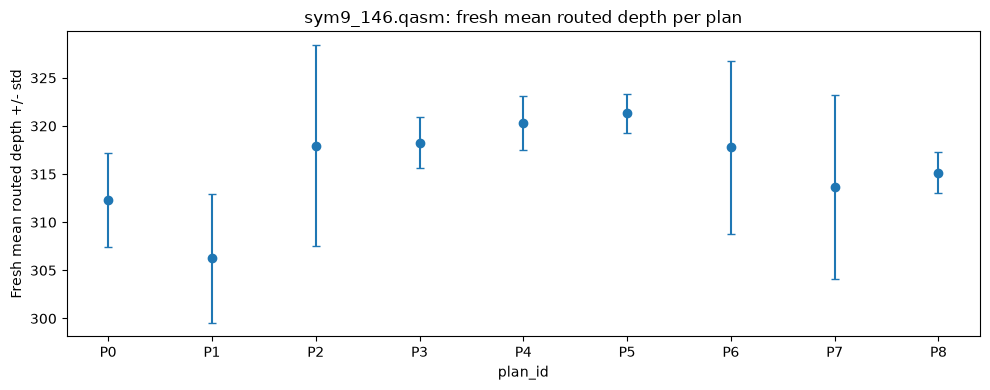

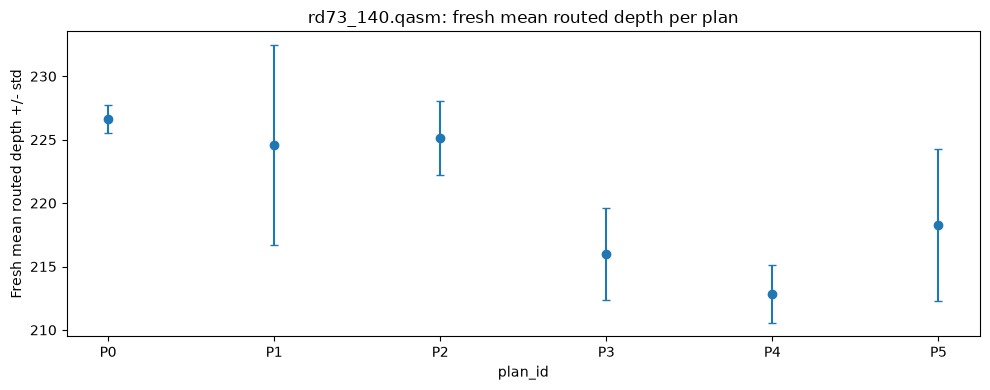

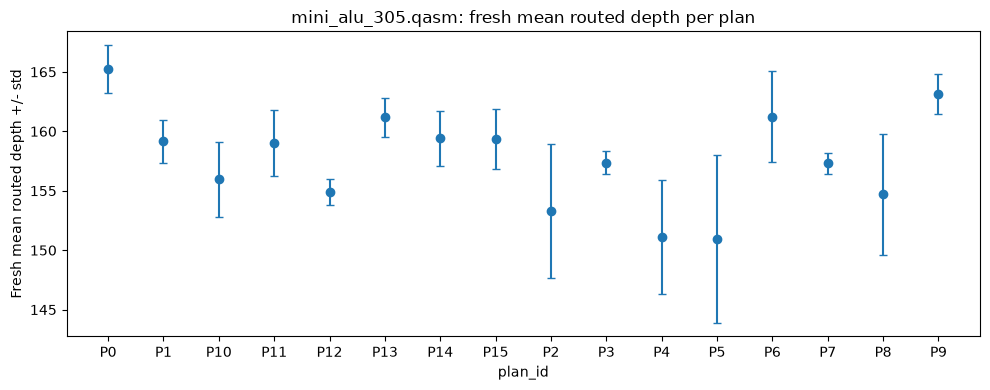

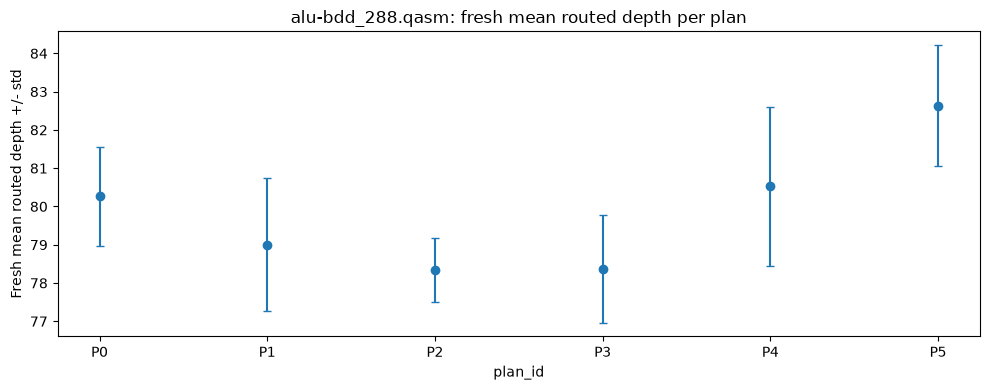

STEP 9 OK: figures saved to C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_fresh30_validation\figures


In [21]:
import matplotlib
print('matplotlib:', matplotlib.__version__)

for circ in CIRCUITS:
    sub = merged[merged['circuit'] == circ]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(sub['mean_swaps'], sub['fresh_mean_swaps'])
    for _, r in sub.iterrows():
        ax.annotate(str(r['plan_id']), (r['mean_swaps'], r['fresh_mean_swaps']), fontsize=7)
    ax.set_xlabel('Old 5-seed mean SWAP')
    ax.set_ylabel('Fresh 30-seed mean SWAP')
    ax.set_title(f'{circ}: old vs fresh mean SWAP')
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{circ}_old5_vs_fresh30_swaps.png', dpi=300)
    plt.show()

for circ in CIRCUITS:
    sub = merged[merged['circuit'] == circ]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(sub['mean_routed_depth'], sub['fresh_mean_routed_depth'])
    for _, r in sub.iterrows():
        ax.annotate(str(r['plan_id']), (r['mean_routed_depth'], r['fresh_mean_routed_depth']), fontsize=7)
    ax.set_xlabel('Old 5-seed mean routed depth')
    ax.set_ylabel('Fresh 30-seed mean routed depth')
    ax.set_title(f'{circ}: old vs fresh mean routed depth')
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{circ}_old5_vs_fresh30_depth.png', dpi=300)
    plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(old_vs_fresh_table['old5_relative_swap_spread_pct'], old_vs_fresh_table['fresh30_relative_swap_spread_pct'])
for _, r in old_vs_fresh_table.iterrows():
    ax.annotate(r['circuit'], (r['old5_relative_swap_spread_pct'], r['fresh30_relative_swap_spread_pct']), fontsize=7)
ax.set_xlabel('Old relative SWAP spread %')
ax.set_ylabel('Fresh relative SWAP spread %')
ax.set_title('Old vs fresh relative SWAP spread')
fig.tight_layout()
fig.savefig(FIG_DIR / 'summary_old_vs_fresh_swap_spread.png', dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(old_vs_fresh_table['old5_relative_depth_spread_pct'], old_vs_fresh_table['fresh30_relative_depth_spread_pct'])
for _, r in old_vs_fresh_table.iterrows():
    ax.annotate(r['circuit'], (r['old5_relative_depth_spread_pct'], r['fresh30_relative_depth_spread_pct']), fontsize=7)
ax.set_xlabel('Old relative routed-depth spread %')
ax.set_ylabel('Fresh relative routed-depth spread %')
ax.set_title('Old vs fresh relative depth spread')
fig.tight_layout()
fig.savefig(FIG_DIR / 'summary_old_vs_fresh_depth_spread.png', dpi=300)
plt.show()

for circ in CIRCUITS:
    sub = fresh30_plan_summary[fresh30_plan_summary['circuit'] == circ].sort_values('plan_id')
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.errorbar(sub['plan_id'], sub['fresh_mean_swaps'], yerr=sub['fresh_std_swaps'], fmt='o', capsize=3)
    ax.set_xlabel('plan_id')
    ax.set_ylabel('Fresh mean SWAP +/- std')
    ax.set_title(f'{circ}: fresh mean SWAP per plan')
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{circ}_fresh_mean_swaps.png', dpi=300)
    plt.show()

for circ in CIRCUITS:
    sub = fresh30_plan_summary[fresh30_plan_summary['circuit'] == circ].sort_values('plan_id')
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.errorbar(sub['plan_id'], sub['fresh_mean_routed_depth'], yerr=sub['fresh_std_routed_depth'], fmt='o', capsize=3)
    ax.set_xlabel('plan_id')
    ax.set_ylabel('Fresh mean routed depth +/- std')
    ax.set_title(f'{circ}: fresh mean routed depth per plan')
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{circ}_fresh_mean_depth.png', dpi=300)
    plt.show()

print('STEP 9 OK: figures saved to', FIG_DIR)

## STEP 10 — Save results (never overwrite original Experiment 1 files)

In [22]:
fresh30_raw.to_csv(OUT_DIR / 'experiment1_fresh30_raw.csv', index=False)
fresh30_plan_summary.to_csv(OUT_DIR / 'experiment1_fresh30_plan_summary.csv', index=False)
fresh30_circuit_summary.to_csv(OUT_DIR / 'experiment1_fresh30_circuit_summary.csv', index=False)
old_vs_fresh_table.to_csv(OUT_DIR / 'experiment1_old5_vs_fresh30_comparison.csv', index=False)
rank_correlations.merge(best_plan_comparison, on=['circuit', 'num_plans']).to_csv(
    OUT_DIR / 'experiment1_old5_vs_fresh30_rank_correlations.csv', index=False)
print('Saved to', OUT_DIR)
for p in sorted(OUT_DIR.glob('*.csv')):
    print(' ', p.name, pd.read_csv(p).shape)
print('Figures:', len(list(FIG_DIR.glob('*.png'))))

Saved to C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_fresh30_validation
  experiment1_fresh30_circuit_summary.csv (5, 15)
  experiment1_fresh30_plan_summary.csv (50, 16)
  experiment1_fresh30_raw.csv (1500, 13)
  experiment1_old5_vs_fresh30_comparison.csv (5, 11)
  experiment1_old5_vs_fresh30_rank_correlations.csv (5, 12)
  fresh30_partial_checkpoint.csv (1500, 13)
Figures: 22


## STEP 11 — Final printed summary

In [23]:
print('number of reconstructed plans:', len(verified_plans))
print('number of signature matches: 50/50')
print('number of fresh physical routing runs:', len(fresh30_raw))
print()
for _, r in fresh30_circuit_summary.iterrows():
    print(f"{r['circuit']}: fresh rel SWAP spread={r['relative_fresh_swap_spread']*100:.2f}% | "
          f"fresh rel depth spread={r['relative_fresh_routed_depth_spread']*100:.2f}%")
print()
for _, r in rank_correlations.iterrows():
    print(f"{r['circuit']}: spearman SWAP={r['spearman_old5_vs_fresh30_swaps']:.3f} | "
          f"spearman depth={r['spearman_old5_vs_fresh30_depth']:.3f}")
print()
print('Interpretation (descriptive only, no statistical proof, no generalization beyond these five circuits):')
print('If fresh relative spreads remain clearly above zero and Spearman correlations are positive,')
print('the Experiment 1 observation — same-width plans differ in physical cost — is robust to a')
print('substantially larger, independent routing-seed sample. This validation does not test any repair algorithm.')

number of reconstructed plans: 50
number of signature matches: 50/50
number of fresh physical routing runs: 1500

system9.qasm: fresh rel SWAP spread=13.36% | fresh rel depth spread=7.23%
sym9_146.qasm: fresh rel SWAP spread=14.77% | fresh rel depth spread=4.92%
rd73_140.qasm: fresh rel SWAP spread=15.36% | fresh rel depth spread=6.47%
mini_alu_305.qasm: fresh rel SWAP spread=12.32% | fresh rel depth spread=9.45%
alu-bdd_288.qasm: fresh rel SWAP spread=12.84% | fresh rel depth spread=5.49%

system9.qasm: spearman SWAP=0.890 | spearman depth=0.803
sym9_146.qasm: spearman SWAP=0.967 | spearman depth=0.717
rd73_140.qasm: spearman SWAP=0.943 | spearman depth=1.000
mini_alu_305.qasm: spearman SWAP=0.931 | spearman depth=0.975
alu-bdd_288.qasm: spearman SWAP=1.000 | spearman depth=0.886

Interpretation (descriptive only, no statistical proof, no generalization beyond these five circuits):
If fresh relative spreads remain clearly above zero and Spearman correlations are positive,
the Experime